#Paquetes necesarios

In [1]:
import cv2
import math
import json
import time
import torch
import easyocr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from pathlib import Path
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText
from ultralytics import YOLO

VIDEO = "C0142.MP4"

c:\Users\pablo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# PRÁCTICA 4: detección de vehículos y matrículas

SEGUIMIENTO: detectamos y seguimos personas y vehículos en el vídeo

In [2]:
model = YOLO("yolo26s.pt")
nombres = {0: "persona", 1: "bicicleta", 2: "coche", 3: "moto", 5: "guagua", 7: "camion"}

detecciones = []               # una por objeto y fotograma, de aquí sale el csv
recorrido = defaultdict(list)  # id -> por dónde ha ido pasando
tipos = defaultdict(list)      # id -> lo que dice yolo que es en cada fotograma

for n_frame, r in enumerate(model.track(VIDEO, show=True, stream=True, persist=True, verbose=False, classes=list(nombres))):
    for caja in r.boxes:
        if caja.id is None:
            continue
        id = int(caja.id)
        x1, y1, x2, y2 = map(int, caja.xyxy[0])
        recorrido[id].append(((x1 + x2) / 2, (y1 + y2) / 2))
        tipos[id].append(nombres[int(caja.cls)])
        detecciones.append({"fotograma": n_frame, "confianza": round(float(caja.conf), 2),
                            "identificador_tracking": id, "x1": x1, "y1": y1, "x2": x2, "y2": y2})

ancho = r.orig_shape[1]
cv2.destroyAllWindows()

CONTEO: contamos solo lo que se mueve, para no contar los coches aparcados

In [3]:
contados = {} # id -> tipo
for id in recorrido:
    tipo = Counter(tipos[id]).most_common(1)[0][0] # el tipo que más veces le ha puesto yolo
    minimo = 0.05 if tipo == "persona" else 0.10   # lo que se tiene que mover (parte del ancho del vídeo)
    if math.dist(recorrido[id][0], recorrido[id][-1]) > minimo * ancho:
        contados[id] = tipo

# nos quedamos solo con las detecciones de lo que se ha contado
detecciones = [d for d in detecciones if d["identificador_tracking"] in contados]
for d in detecciones:
    d["tipo_objeto"] = contados[d["identificador_tracking"]]

print("Total:", len(contados))
print(Counter(contados.values()))

Total: 51
Counter({'coche': 28, 'persona': 18, 'moto': 3, 'guagua': 1, 'bicicleta': 1})


TRAIN: entrenamos yolo11n para detectar matrículas

In [4]:
#model = YOLO("yolo11n.pt")
#model.train(data="dataset.yaml", epochs=100, imgsz=1920, batch=8, patience=20, name="detector_matriculas")

ANÁLISIS DEL ENTRENAMIENTO: gráficas que genera yolo al entrenar

Pérdidas y métricas de cada época:

![Entrenamiento](detector_matriculas-3/results.png)

Curva precisión-recall y matriz de confusión en validación:

![PR](detector_matriculas-3/BoxPR_curve.png)

![Matriz de confusión](detector_matriculas-3/confusion_matrix.png)

TEST: métricas del modelo con las fotos de test

In [ ]:
model_mat = YOLO("best.pt")

metrics = model_mat.val(data="dataset.yaml", split="test", imgsz=1920, batch=4, conf=0.35, plots=True, workers=2)
print("mAP50:", round(metrics.box.map50, 3), " mAP50-95:", round(metrics.box.map, 3))
print("Gráficas en:", metrics.save_dir)

# liberamos memoria gráfica
del metrics
torch.cuda.empty_cache()


Ultralytics 8.4.202  Python-3.14.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 8192MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1209.4±674.3 MB/s, size: 3260.3 KB)
val: Scanning C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\labels.cache... 237 images, 0 backgrounds, 8 corrupt: 100% ━━━━━━━━━━━━ 237/237 31.1Mit/s 0.0s
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\images\njhm-013.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [ 535.       1019.5        63.         23.5       119.510666 1026.34
   35.277245   10.799789]
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\images\njhm-016.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [543.       818.86945  105.        44.738846]
val: C:\Users\pablo\Desktop\INFORMATICA\Apuntes_4\VC\P4\P4\dataset\test\im

MATRÍCULAS: buscamos la matrícula dentro de cada vehículo contado

In [6]:
model_mat = YOLO("best.pt")
recortes = defaultdict(list) # id -> fotos de su matrícula, para leerlas luego con el OCR

por_fotograma = defaultdict(list)
for d in detecciones:
    por_fotograma[d["fotograma"]].append(d)

cap = cv2.VideoCapture(VIDEO)
for n_frame in range(max(por_fotograma) + 1):
    ok, frame = cap.read()
    for d in por_fotograma[n_frame]:
        if d["tipo_objeto"] == "persona":
            continue
        mat = model_mat(frame[d["y1"]:d["y2"], d["x1"]:d["x2"]], conf=0.3, verbose=False)[0].boxes
        if len(mat) == 0:
            continue
        mx1, my1, mx2, my2 = map(int, mat.xyxy[0])
        mx1, my1, mx2, my2 = d["x1"] + mx1, d["y1"] + my1, d["x1"] + mx2, d["y1"] + my2 # del recorte a la imagen entera
        d.update({"matrícula_en_su_caso": 1, "confianza_matricula": round(float(mat.conf[0]), 2),
                  "mx1": mx1, "my1": my1, "mx2": mx2, "my2": my2})
        # guardamos la foto de la matrícula si se ve grande (máximo 10 por vehículo)
        id = d["identificador_tracking"]
        if mx2 - mx1 >= 30 and len(recortes[id]) < 10:
            recortes[id].append(frame[my1:my2, mx1:mx2].copy())
cap.release()

# PRÁCTICA 4b: reconocimiento de caracteres en matrículas

OCR: probamos EasyOCR (OCR clásico) y SmolVLM (un VLM al que le preguntamos qué pone)

In [7]:
torch.cuda.empty_cache() # liberamos la memoria de la gráfica que ha dejado yolo

lector = easyocr.Reader(["es"])

procesador = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct", do_image_splitting=False)
vlm = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-Instruct", dtype=torch.bfloat16).to("cuda")
pregunta = procesador.apply_chat_template([{"role": "user", "content": [
    {"type": "image"}, {"type": "text", "text": "Read the license plate. Answer only with its characters."}]}],
    add_generation_prompt=True)


def limpiar(texto):
    # solo letras y números, en mayúsculas
    return "".join(c for c in texto.upper() if c.isalnum())


def leer_easyocr(recorte):
    return limpiar("".join(lector.readtext(recorte, detail=0)))


def leer_smolvlm(recorte):
    imagen = Image.fromarray(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
    entrada = procesador(text=pregunta, images=[imagen], return_tensors="pt").to("cuda")
    salida = vlm.generate(**entrada, max_new_tokens=12, do_sample=False)
    respuesta = salida[0][entrada["input_ids"].shape[1]:] # solo lo que contesta, sin la pregunta
    return limpiar(procesador.decode(respuesta, skip_special_tokens=True))

Loading weights: 100%|██████████| 657/657 [00:02<00:00, 258.75it/s]


TEXTO DE LAS MATRÍCULAS: leemos las fotos de cada matrícula con SmolVLM y nos quedamos con la lectura que más se repite

In [8]:
texto_matricula = {} # id -> matrícula
for id, fotos in recortes.items():
    lecturas = [leer_smolvlm(foto) for foto in fotos]
    texto_matricula[id] = Counter(lecturas).most_common(1)[0][0]

for d in detecciones:
    d["texto_matricula"] = texto_matricula.get(d["identificador_tracking"], "")

print(texto_matricula)

{1: '324', 10: '13222222', 13: '3713LKG', 17: '571KSS', 22: '5564455', 20: 'CGUG', 27: 'K23LKZ', 26: '6713HCR', 30: '2916FGN', 34: '9786LCF', 41: '227671', 37: '0053JFM', 45: '0285FKZ', 43: '3902FXD', 49: '3685KWN', 56: '9059LYY', 62: 'BS36LKJ', 74: '4333', 75: '8025JB', 76: '1770JVG', 88: '7339L66', 90: '8098JXM', 94: 'GC52730W', 95: 'S143LC', 92: '1965KBP', 98: '1516', 103: 'S017HDD'}


CSV: guardamos todas las detecciones con su matrícula en `resultado.csv`

In [9]:
columnas = ["fotograma", "tipo_objeto", "confianza", "identificador_tracking", "x1", "y1", "x2", "y2",
            "matrícula_en_su_caso", "confianza_matricula", "mx1", "my1", "mx2", "my2", "texto_matricula"]
pd.DataFrame(detecciones, columns=columnas).to_csv("resultado.csv", index=False, float_format="%g")

VÍDEO: pintamos las cajas, las matrículas y el total en `resultado.mp4`

In [10]:
personas = list(contados.values()).count("persona")
total = f"Personas: {personas}  Vehiculos: {len(contados) - personas}"

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
tamano = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
video = cv2.VideoWriter("resultado.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, tamano)

n_frame = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    for d in por_fotograma[n_frame]:
        cv2.rectangle(frame, (d["x1"], d["y1"]), (d["x2"], d["y2"]), (0, 255, 0), 2)
        cv2.putText(frame, f"{d['tipo_objeto']} {d['identificador_tracking']}", (d["x1"], d["y1"] - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        if "mx1" in d:
            cv2.rectangle(frame, (d["mx1"], d["my1"]), (d["mx2"], d["my2"]), (0, 255, 255), 1)
            cv2.putText(frame, d["texto_matricula"], (d["mx1"], d["my2"] + 15),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)

    cv2.putText(frame, total, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    video.write(frame)
    cv2.imshow("resultado", frame) # lo vamos viendo mientras se guarda
    cv2.waitKey(1)
    n_frame += 1

cap.release()
video.release()
cv2.destroyAllWindows()

COMPARATIVA: los dos leen las matrículas de las fotos de test y miramos cuántas aciertan y cuánto tardan

In [11]:
muestras = [] # (lo que pone de verdad, recorte de la matrícula)
for foto in Path("dataset/test/images").iterdir():
    img = cv2.imread(str(foto))
    alto, ancho = img.shape[:2]
    for a in json.load(open(f"dataset_2/annotations/{foto.stem}.json", encoding="utf-8")):
        real = limpiar(str(a["plate"]))
        cx, cy, w, h = a["rectangle"]
        x1, y1 = int((cx - w / 2) * ancho), int((cy - h / 2) * alto)
        x2, y2 = int((cx + w / 2) * ancho), int((cy + h / 2) * alto)
        if len(real) >= 6 and cx <= 1 and x2 - x1 >= 10: # con texto apuntado y la caja bien
            muestras.append((real, img[y1:y2, x1:x2].copy())) # copy() para no guardar la foto entera en memoria
muestras = muestras[:100] # con 100 matrículas es suficiente para comparar
print(len(muestras), "matrículas")

100 matrículas


         acierto  segundos
modelo                    
EasyOCR     0.35  0.052421
SmolVLM     0.78  0.796540


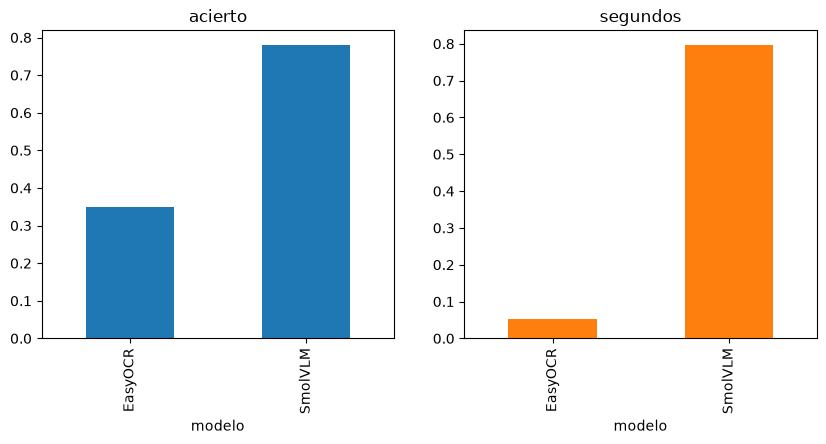

In [12]:
resultados = []
for modelo, leer in [("EasyOCR", leer_easyocr), ("SmolVLM", leer_smolvlm)]:
    for real, recorte in muestras:
        inicio = time.time()
        leido = leer(recorte)
        resultados.append({"modelo": modelo, "acierto": leido == real, "segundos": time.time() - inicio})

resumen = pd.DataFrame(resultados).groupby("modelo").mean()
print(resumen)
resumen.plot.bar(subplots=True, layout=(1, 2), figsize=(10, 4), legend=False)
plt.savefig("ocr_comparativa.png")